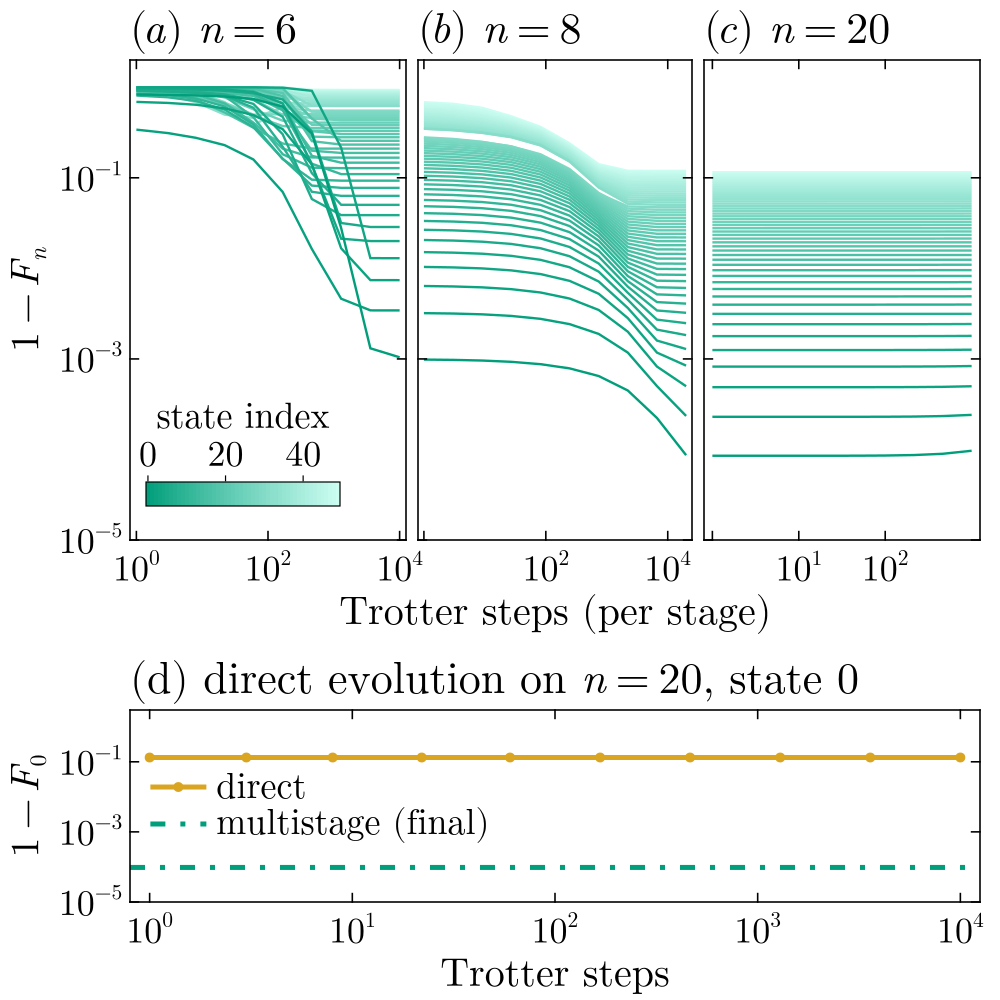

In [1]:
using CairoMakie, XLSX, LaTeXStrings

multistage_file = joinpath(@__DIR__, "plot_data_N6_N8_N20_run2.xlsx")
direct_file     = joinpath(@__DIR__, "plot_data_N20.xlsx")
outfile         = joinpath(@__DIR__, "infidelity_vs_trotter_steps.pdf")

gold = RGBf(0.855, 0.647, 0.125)

top_xticks = Dict(6 => [1e0, 1e2, 1e4], 8 => [1e0, 1e2, 1e4], 20 => [1e0, 1e1, 1e2])
bottom_xticks = [1e0, 1e1, 1e2, 1e3, 1e4]
yticks_vals = [1e-5, 1e-3, 1e-1]

set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false, ygridvisible = false,
        spinewidth = 0.8,
        xtickwidth = 0.8, ytickwidth = 0.8,
        xticksize = 5, yticksize = 5,
        xtickalign = 1, ytickalign = 1,
        xticksmirrored = true, yticksmirrored = true,
        xticklabelpad = 3, yticklabelpad = 3,
        xticklabelsize = 18, yticklabelsize = 18,
        titlesize = 22, titlegap = 3, titlealign = :left,
        xlabelsize = 20, ylabelsize = 20,
        ylabelpadding = 4,
    ),
))

function read_runs(path)
    xf = XLSX.readxlsx(path)
    runs = []
    for name in XLSX.sheetnames(xf)
        m = match(r"^n=(\d+)$", name)
        m === nothing && continue
        tbl  = XLSX.getdata(xf[name])
        hdr  = string.(tbl[1, :])
        body = tbl[2:end, :]
        col(j) = (v = body[:, j]; i = findlast(!ismissing, v);
                  [ismissing(x) ? NaN : Float64(x) for x in v[1:i]])
        F = Dict{Int,Vector{Float64}}()
        for (j, h) in enumerate(hdr)
            mm = match(r"^F \(state (\d+)\)$", h)
            mm === nothing || (F[parse(Int, mm[1])] = col(j))
        end
        steps = col(findfirst(==("Trotter step"), hdr))
        push!(runs, (N = parse(Int, m[1]), steps = steps, F = F))
    end
    sort!(runs; by = r -> r.N)
end

positive(x) = [v > 0 ? v : NaN for v in x]
infid(F)    = positive(1 .- F)
xmax(steps) = maximum(filter(isfinite, steps))

pow10(v) = latexstring("10^{", round(Int, log10(v)), "}")
ticks(vals; hide_first = false) =
    (vals, [hide_first && i == 1 ? " " : pow10(v) for (i, v) in enumerate(vals)])

function style_axis!(ax, xhi, xt, yhi; hide_first = false, ylabels = true)
    ax.xticks = ticks(xt; hide_first)
    ax.yticks = ticks(yticks_vals)
    ax.yticklabelsvisible = ylabels
    xlims!(ax, 0.8, 1.25 * xhi)
    ylims!(ax, 1e-5, yhi)
end

multi  = read_runs(multistage_file)
direct = read_runs(direct_file)[1]

nstates = maximum(maximum(keys(r.F)) for r in multi) + 1
c0 = (0.00, 0.62, 0.48)
c1 = (0.55, 0.98, 0.88) .+ 0.55 .* (1 .- (0.55, 0.98, 0.88))
colors = [RGBf(((1 - t) .* c0 .+ t .* c1)...) for t in range(0, 1; length = nstates) .^ 0.9]

fig = Figure(size = (500, 500), backgroundcolor = :white, figure_padding = (4, 10, 4, 4))
n = length(multi)

top_axes = Axis[]
for (p, r) in enumerate(multi)
    ax = Axis(fig[1, p]; xscale = log10, yscale = log10,
              title = latexstring("(", 'a' + p - 1, ")\\ n=", r.N),
              ylabel = p == 1 ? L"$1-F_n$" : "")
    x = positive(r.steps)
    for id in sort(collect(keys(r.F)); rev = true)
        y = infid(r.F[id])
        lines!(ax, x[1:length(y)], y; color = colors[id + 1], linewidth = 1.2)
    end
    style_axis!(ax, xmax(r.steps), top_xticks[r.N], 2.0; hide_first = p > 1, ylabels = p == 1)
    push!(top_axes, ax)
end

Label(fig[2, 1:n], L"\mathrm{Trotter\ steps\ (per\ stage)}"; fontsize = 20, tellwidth = false)

bax = Axis(fig[3, 1:n]; xscale = log10, yscale = log10,
           title = L"(d) direct evolution on $n=20$, state 0",
           xlabel = L"\mathrm{Trotter\ steps}", xlabelpadding = 2,
           ylabel = L"$1-F_0$")

y_dir = infid(direct.F[0])
x_dir = positive(direct.steps)
lines!(bax, x_dir, y_dir; color = gold, linewidth = 2.5)
scatter!(bax, x_dir, y_dir; color = gold, marker = :circle, markersize = 7, strokewidth = 0)

ref = infid(multi[findfirst(r -> r.N == direct.N, multi)].F[0])
hlines!(bax, [ref[findlast(isfinite, ref)]]; color = colors[1], linestyle = :dashdot, linewidth = 2.5)

style_axis!(bax, xmax(direct.steps), bottom_xticks, 3.0)

axislegend(bax,
    [[LineElement(color = gold, linewidth = 2.5),
      MarkerElement(marker = :circle, markersize = 7, color = gold, strokewidth = 0)],
     LineElement(color = colors[1], linestyle = :dashdot, linewidth = 2.5)],
    [L"\mathrm{direct}", L"\mathrm{multistage\ (final)}"];
    position = :lc, margin = (6, 6, 6, 6), labelsize = 18,
    patchsize = (28, 10), patchlabelgap = 5, rowgap = 0,
    framevisible = false, padding = (4, 4, 4, 4))

box = lift(top_axes[1].scene.viewport) do vp
    W, H = vp.widths
    Rect2f(vp.origin[1] + 0.06W, vp.origin[2] + 0.07H, 0.70W, 12)
end
cb = Colorbar(fig; bbox = box,
    colormap = cgrad(colors; categorical = true),
    limits = (-0.5, nstates - 0.5),
    vertical = false, flipaxis = true, size = 12,
    ticks = ([0, 20, 40], [L"0", L"20", L"40"]),
    ticklabelsize = 18, ticklabelpad = 1,
    ticksize = 3, tickwidth = 0.6, tickalign = 0,
    spinewidth = 0.6,
    label = L"$$state index", labelsize = 18, labelpadding = 1)
translate!(cb.blockscene, 0, 0, 100)

colgap!(fig.layout, 6)
rowgap!(fig.layout, 1, 2)
rowgap!(fig.layout, 2, 12)
rowsize!(fig.layout, 1, Auto(1.25))
rowsize!(fig.layout, 3, Auto(0.5))

save(outfile, fig)
save(replace(outfile, r"\.pdf$" => ".png"), fig; px_per_unit = 4)
fig

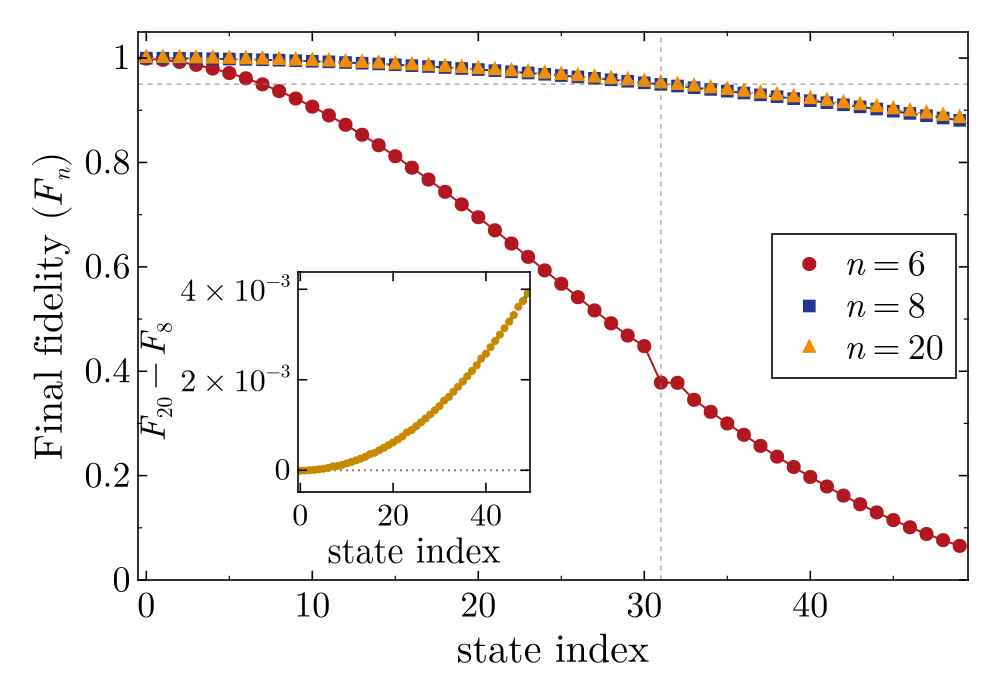

In [2]:
using CairoMakie, XLSX, LaTeXStrings

datafile = joinpath(@__DIR__, "plot_data_N6_N8_N20_run2.xlsx")
outfile  = joinpath(@__DIR__, "final_fidelity_multistage.pdf")
qubits   = [6, 8, 20]

palette    = [RGBf(0.698, 0.090, 0.122), RGBf(0.122, 0.216, 0.569), RGBf(0.949, 0.557, 0.024)]
markers    = [:circle, :rect, :utriangle]
linestyles = [:solid, :dash, :dot]
yellow     = RGBf(0.788, 0.533, 0.000)
green      = RGBf(0.106, 0.541, 0.447)

set_theme!(Theme(
    fontsize = 11,
    font = "Times New Roman",
    Axis = (
        xgridvisible = false, ygridvisible = false,
        xlabelsize = 20, ylabelsize = 20,
        xticklabelsize = 18, yticklabelsize = 18,
        spinewidth = 0.8, xtickwidth = 0.8, ytickwidth = 0.8,
        xticksize = 5, yticksize = 5,
        xminorticksize = 2.5, yminorticksize = 2.5,
        xminortickwidth = 0.6, yminortickwidth = 0.6,
        xminorticksvisible = true, yminorticksvisible = true,
        xticklabelpad = 3, yticklabelpad = 3,
        xtickalign = 1, ytickalign = 1,
        xminortickalign = 1, yminortickalign = 1,
        xticksmirrored = true, yticksmirrored = true,
    ),
))

function texnum(v)
    v == 0 && return L"0"
    e = floor(Int, log10(abs(v)))
    trim(x) = replace(string(x), r"\.0$" => "")
    -2 <= e <= 3 ? latexstring(trim(round(v; sigdigits = 4))) :
                   latexstring(trim(round(v / 10.0^e; sigdigits = 4)), "\\times10^{", e, "}")
end

function nice_ticks(lo, hi, n)
    raw  = (hi - lo) / n
    mag  = 10.0^floor(log10(raw))
    step = mag * first(m for m in (1, 2, 5, 10) if raw <= m * mag)
    vals = [k * step for k in ceil(lo / step - 1e-9):floor(hi / step + 1e-9)]
    (vals, texnum.(vals))
end

function final_fidelities(path)
    xf = XLSX.readxlsx(path)
    F = Dict{Int,Vector{Float64}}()
    for name in XLSX.sheetnames(xf)
        m = match(r"^n=(\d+)$", name)
        m === nothing && continue
        tbl = XLSX.getdata(xf[name])
        hdr = string.(tbl[1, :])
        cols = Tuple{Int,Int}[]
        for (j, h) in enumerate(hdr)
            mm = match(r"^F \(state (\d+)\)$", h)
            mm === nothing || push!(cols, (parse(Int, mm[1]), j))
        end
        sort!(cols)
        F[parse(Int, m[1])] = [begin
            v = filter(x -> !ismissing(x) && isfinite(x), tbl[2:end, j])
            isempty(v) ? NaN : Float64(last(v))
        end for (_, j) in cols]
    end
    F
end

F = final_fidelities(datafile)
n = length(F[qubits[1]])
x = 0:n-1

fig = Figure(size = (500, 350), backgroundcolor = :white)

ax = Axis(fig[1, 1];
    xlabel = L"\mathrm{state\ index}",
    ylabel = L"\mathrm{Final\ fidelity}\ (F_n)",
    limits = (-0.5, n - 0.5, 0, 1.05),
    xticks = nice_ticks(0, n - 1, 5),
    yticks = (0:0.2:1, texnum.(0:0.2:1)))

handles = map(enumerate(qubits)) do (i, q)
    lines!(ax, x, F[q]; color = palette[i], linewidth = 1.0, linestyle = linestyles[i])
    scatter!(ax, x, F[q]; color = palette[i], marker = markers[i], markersize = 10, strokewidth = 0)
end

above = findall(F[20] .> 0.95)
k = above[argmin(F[20][above])] - 1
hlines!(ax, [0.95]; color = (:grey, 0.6), linewidth = 0.8, linestyle = :dash)
vlines!(ax, [k];    color = (:grey, 0.6), linewidth = 0.8, linestyle = :dash)

axislegend(ax, handles, [latexstring("n=", q) for q in qubits];
    position = :rc, framevisible = true, framewidth = 0.8,
    labelsize = 18, patchsize = (25, 10), padding = (6, 6, 6, 6))

dF  = F[20] .- F[8]
fin = filter(isfinite, dF)
lo, hi = min(minimum(fin), 0.0), max(maximum(fin), 0.0)
pad = hi > lo ? 0.12 * (hi - lo) : 1e-6
ylo, yhi = lo - pad, hi + pad

box = lift(ax.scene.viewport) do vp
    W, H = vp.widths
    Rect2f(vp.origin[1] + 80, vp.origin[2] + 44, 0.28W, 0.40H)
end

inset = Axis(fig; bbox = box, backgroundcolor = :white,
    xlabel = L"\mathrm{state\ index}", ylabel = L"F_{20}-F_{8}",
    xlabelsize = 18, ylabelsize = 18,
    xticklabelsize = 16, yticklabelsize = 16,
    xlabelpadding = 1, ylabelpadding = 2,
    xminorticksvisible = false, yminorticksvisible = false,
    xticks = nice_ticks(0, n - 1, 3),
    yticks = nice_ticks(ylo, yhi, 3),
    limits = (-0.5, n - 0.5, ylo, yhi))
translate!(inset.blockscene, 0, 0, 100)

hlines!(inset, 0; color = :gray, linestyle = :dot, linewidth = 1)
lines!(inset, x, dF; color = green, linestyle = :dash, linewidth = 2.0)
scatter!(inset, x, dF; color = yellow, marker = :circle, markersize = 5,
         strokecolor = yellow, strokewidth = 0.5)

save(outfile, fig)
save(replace(outfile, r"\.pdf$" => ".png"), fig; px_per_unit = 3)
fig